# Prevendo a classe da busca

A `query_class` é o sinal mais forte do EDA (a classe do produto bate com ela em 64% dos pares Exact e em 4% dos Irrelevant), mas não existe na hora da busca. A ideia aqui é **prever a classe só a partir do texto**, sem rótulos, e ver se vale a pena usá-la no retrieval ou no ranking.

A `query_class` real entra só como gabarito. Todas as escolhas usam treino e validação; o teste não é tocado.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from product_search.engine import SearchEngine
from product_search.evaluation.metrics import paired_bootstrap, recall
from product_search.evaluation.runs import load_dataset

sns.set_theme(style="whitegrid", context="notebook")
ORDER = ["Exact", "Partial", "Irrelevant"]
PALETTE = {"Exact": "#2a9d8f", "Partial": "#e9c46a", "Irrelevant": "#adb5bd"}

data = load_dataset()
engine = SearchEngine.load(with_ranker=False)
products, model = engine.products, engine.dense.model
queries = pd.concat([data.queries[s].assign(split=s) for s in ["train", "val"]], ignore_index=True)

product_classes = products.product_class.str.split("|").map(lambda cs: {c.strip() for c in cs if c.strip()})
exploded = product_classes.map(list).explode().dropna()
CLASSES = sorted(exploded.unique())
known = queries.query_class.isin(CLASSES)
print(f"{len(CLASSES)} classes no catálogo | {len(queries)} queries de treino+validação")
print(f"{known.sum()} queries têm a query_class entre as classes do catálogo")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 22882.06it/s]

601 classes no catálogo | 383 queries de treino+validação
375 queries têm a query_class entre as classes do catálogo


## 1. Três jeitos de representar uma classe

- **nome:** o embedding do nome da classe ("Bar Stools").
- **nome + categoria:** o nome mais o caminho de categoria mais comum dos produtos da classe.
- **centróide:** a média dos embeddings dos produtos da classe (os mesmos usados no retrieval).

E um baseline sem embeddings de classe: **consenso do retrieval**, a classe mais frequente entre os 20 primeiros candidatos do híbrido.

In [2]:
by_class = exploded.groupby(exploded).groups
top_category = {c: products.category_hierarchy.iloc[list(idx)].mode().iat[0] for c, idx in by_class.items()}


def normalize(m):
    return m / np.linalg.norm(m, axis=1, keepdims=True)


class_vectors = {
    "nome": model.encode(CLASSES, normalize_embeddings=True),
    "nome + categoria": model.encode([f"{c}. {top_category[c]}" for c in CLASSES], normalize_embeddings=True),
    "centróide": normalize(np.stack([engine.dense.embeddings[list(by_class[c])].mean(axis=0) for c in CLASSES])),
}
query_vectors = model.encode(queries["query"].tolist(), normalize_embeddings=True)


def top_classes(scores, k=5):
    return [[CLASSES[i] for i in np.argsort(-row)[:k]] for row in scores]


predictions = {name: top_classes(query_vectors @ vectors.T) for name, vectors in class_vectors.items()}


def consensus(query, depth=20):
    counts = Counter(c for i in engine.retrieve(query).candidates[:depth] for c in product_classes.iat[i])
    return [c for c, _ in counts.most_common(5)]


predictions["consenso do retrieval"] = [consensus(q) for q in queries["query"]]

split                  train                  val              
k                      top-1  top-3  top-5  top-1  top-3  top-5
método                                                         
centróide              0.577  0.772  0.822  0.489  0.755  0.830
consenso do retrieval  0.794  0.911  0.922  0.745  0.904  0.926
nome                   0.441  0.616  0.669  0.468  0.596  0.670
nome + categoria       0.342  0.577  0.662  0.330  0.489  0.628

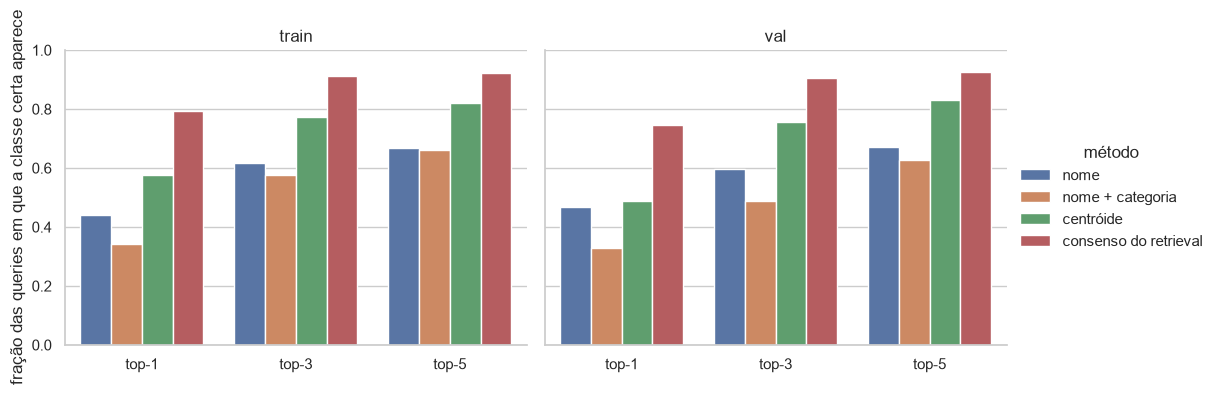

In [3]:
rows = []
for method, preds in predictions.items():
    for k in (1, 3, 5):
        hit = pd.Series([qc in p[:k] for qc, p in zip(queries.query_class, preds, strict=True)])
        for split in ["train", "val"]:
            mask = known & (queries.split == split)
            rows.append({"método": method, "k": f"top-{k}", "split": split, "acerto": hit[mask].mean()})
accuracy = pd.DataFrame(rows)

g = sns.catplot(accuracy, x="k", y="acerto", hue="método", col="split", kind="bar", height=4, aspect=1.3, palette="deep")
g.set_axis_labels("", "fração das queries em que a classe certa aparece")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.set_ylim(0, 1)

accuracy.pivot_table(index="método", columns=["split", "k"], values="acerto").round(3)

In [4]:
best = accuracy[(accuracy.split == "train") & (accuracy.k == "top-1")].set_index("método").acerto.idxmax()
queries["predicted"] = [p[0] for p in predictions[best]]
queries["predicted_top3"] = [p[:3] for p in predictions[best]]
print(f"escolhido no treino: {best}")
queries.loc[known].sample(10, random_state=0)[["query", "query_class", "predicted"]]

escolhido no treino: consenso do retrieval


,query,query_class,predicted
126,bee,Glassware & Barware,Beekeeping Supplies
302,orren ellis l shape desk,Desks,Desks
318,wine bar,Bars & Bar Sets,Bars & Bar Sets
215,croscill ashton,Accent Pillows,Wall Art
209,tressler rug,Area Rugs,Area Rugs
104,black freestanding tub with faucet,Tubs And Whirlpools,Tubs And Whirlpools
254,butcher block island,Kitchen Islands,Kitchen Islands
149,retractable side awning,Awnings,Awnings
77,wire basket with dividers,"Boxes, Bins, Baskets, & Buckets","Boxes, Bins, Baskets, & Buckets"
53,filaret outdoor sofa,Patio Sofas,Patio Sofas


- O **consenso do retrieval** é o melhor de longe: acerta a classe no top-1 em 75% das buscas da validação e chega a 90% no top-3. O retrieval já "sabe" a classe; basta contar.
- O embedding do nome da classe sozinho acerta menos da metade. Juntar a categoria piora: o caminho de categoria é genérico ("Furniture / ...") e dilui o nome.
- O centróide fica no meio (49% no top-1 da validação), mas 83% no top-5.
- Os erros vêm de buscas ambíguas ou só com marca: "bee" vira apicultura, "croscill ashton" (uma linha de almofadas) vira quadro.

## 2. A classe prevista separa os rótulos?

Se separar, vale como feature do ranking: "a classe do produto bate com a classe prevista para a busca". Para comparar, a mesma conta com a `query_class` real, que é o teto.

label,Exact,Partial,Irrelevant
classe,,,
prevista (top-1),0.633,0.508,0.057
prevista (top-3),0.786,0.631,0.104
real (teto),0.702,0.518,0.055


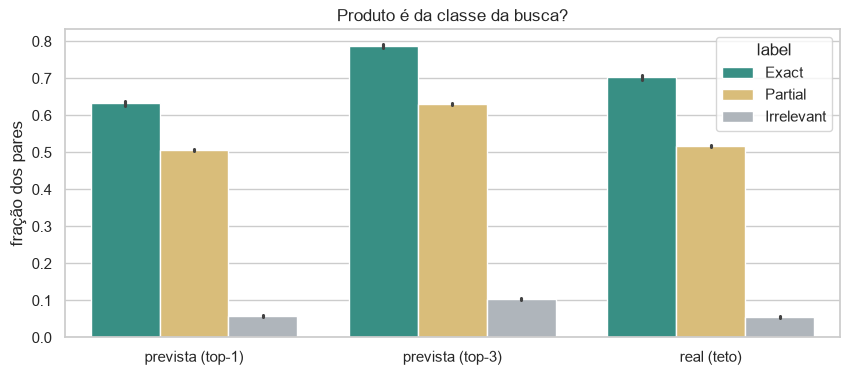

In [5]:
labels = pd.concat(
    [
        pd.DataFrame({"query_id": qid, "product_id": list(lab), "label": list(lab.values())})
        for qid, lab in data.qrels.items()
        if qid in set(queries.query_id)
    ],
    ignore_index=True,
)
classes_by_id = dict(zip(products.product_id, product_classes, strict=True))
q = queries.set_index("query_id")
pairs = list(zip(labels.query_id, labels.product_id, strict=True))
labels["prevista (top-1)"] = [q.predicted[qi] in classes_by_id[p] for qi, p in pairs]
labels["prevista (top-3)"] = [bool(set(q.predicted_top3[qi]) & classes_by_id[p]) for qi, p in pairs]
labels["real (teto)"] = [q.query_class[qi] in classes_by_id[p] for qi, p in pairs]

match = labels.melt(
    id_vars="label", value_vars=["prevista (top-1)", "prevista (top-3)", "real (teto)"], var_name="classe", value_name="bate"
)
ax = sns.barplot(match, x="classe", y="bate", hue="label", hue_order=ORDER, palette=PALETTE)
ax.set(title="Produto é da classe da busca?", xlabel="", ylabel="fração dos pares")
plt.gcf().set_size_inches(10, 4)

match.groupby(["classe", "label"]).bate.mean().unstack()[ORDER].round(3)

- A classe prevista separa os rótulos **quase tão bem quanto a real**: o produto é da classe prevista em 63% dos pares Exact e em 6% dos Irrelevant. Com a `query_class` real, 70% e 5,5%.
- É uma boa candidata a feature do ranking: "o produto é da classe prevista para a busca?". Ela entra no próximo teste, junto com as ideias 5 a 7, e a ablação diz se agrega. O ranker já tem `class_overlap` e os scores do retrieval, que capturam parte disso.
- Mesmo com a classe **real**, 30% dos produtos Exact são de outra classe (classes vizinhas, como banqueta de bar e de balcão). Por isso a classe não pode virar filtro.

## 3. Bônus no retrieval

Busco 300 candidatos no híbrido e adianto em `B` posições os produtos da classe prevista (top-1). Os 100 primeiros dessa nova ordem são os candidatos. Testo duas previsões: o **consenso** (vem do próprio retrieval) e o **centróide** (independente dele). `B` é escolhido pelo Recall@100 no treino e o resultado é reportado na validação, com bootstrap pareado contra o híbrido atual (`B = 0`).

consenso do retrieval: B=50 | validação 0.6813 -> 0.6843 | diff 0.003 IC [np.float64(-0.0025), np.float64(0.0096)]
centróide: B=25 | validação 0.6813 -> 0.6788 | diff -0.0025 IC [np.float64(-0.0062), np.float64(0.0007)]


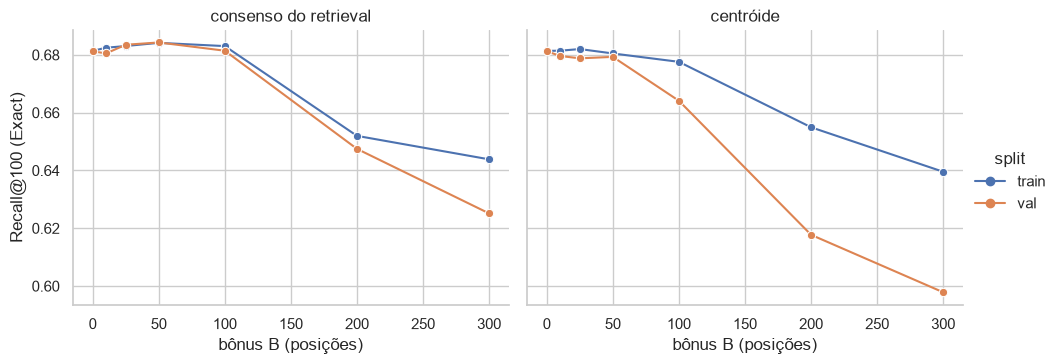

In [6]:
pids = products.product_id.to_numpy()
pools = {qid: engine.retrieve(text, k=300).candidates for qid, text in zip(queries.query_id, queries["query"], strict=True)}
predicted_by = {
    m: dict(zip(queries.query_id, (p[0] for p in predictions[m]), strict=True)) for m in ["consenso do retrieval", "centróide"]
}


def boosted_recall(qid, bonus, method):
    pool = pools[qid]
    in_class = np.array([predicted_by[method][qid] in product_classes.iat[i] for i in pool])
    order = np.argsort(np.arange(len(pool)) - bonus * in_class, kind="stable")
    return recall(pids[pool[order]].tolist(), data.qrels[qid])


BONUS = [0, 10, 25, 50, 100, 200, 300]
ids = {s: queries.query_id[queries.split == s].tolist() for s in ["train", "val"]}
curve = pd.DataFrame(
    [
        {"método": m, "B": b, "split": s, "recall@100": np.nanmean([boosted_recall(qid, b, m) for qid in ids[s]])}
        for m in predicted_by
        for b in BONUS
        for s in ids
    ]
)
g = sns.relplot(curve, x="B", y="recall@100", hue="split", col="método", kind="line", marker="o", height=3.8, aspect=1.3)
g.set_axis_labels("bônus B (posições)", "Recall@100 (Exact)")
g.set_titles("{col_name}")

for m in predicted_by:
    chosen = curve[(curve.split == "train") & (curve["método"] == m)].set_index("B")["recall@100"].idxmax()
    base = [boosted_recall(qid, 0, m) for qid in ids["val"]]
    boost = [boosted_recall(qid, chosen, m) for qid in ids["val"]]
    ci = paired_bootstrap(base, boost)
    print(f"{m}: B={chosen} | validação {np.nanmean(base):.4f} -> {np.nanmean(boost):.4f} | diff {ci['diff']} IC {ci['ci95']}")

- **O bônus não ajuda o retrieval.** Com o consenso, +0,003 de Recall@100, com o IC passando pelo zero. Com o centróide, −0,003. Bônus maiores pioram nos dois casos.
- Os dois motivos: o consenso vem do próprio retrieval, então só reforça o que já estava lá; e, como 30% dos Exact são de outra classe, empurrar a classe prevista tira dos 100 candidatos produtos bons de classes vizinhas.
- Um efeito colateral: fundir listas de 300 em vez de 100 (o `B = 0` daqui) já dá 0,681 contra 0,677 do retrieval atual. É pequeno, mas mostra que a profundidade das listas no RRF é um parâmetro a ajustar.

## Decisão

Não mudo o retrieval. A classe prevista pelo consenso vai para o ranking como feature candidata, e a ablação decide se fica.

## Resultado no ranking: não adotada

Testei a classe prevista como feature do ranking (`class_share`: fração dos 20 primeiros candidatos que são da mesma classe do produto), junto com as outras features da tentativa v2. Validação, nDCG@10:

| Variante | nDCG@10 | contra a v1 |
|---|---|---|
| v1 (modelo final) | 0,786 | — |
| v2 (v1 + todas as novas) | 0,792 | +0,006, IC [−0,006; +0,018] |
| v2 sem `class_share` | 0,791 | +0,005, IC [−0,004; +0,015] |

- Tirar a `class_share` da v2 muda o nDCG@10 em 0,001: ela não agrega nada mensurável.
- Numa primeira versão da v2, com o vocabulário de atributos ainda errado, a mesma conta sugeria que a `class_share` respondia por quase todo o ganho. A conclusão inverteu com uma mudança em outras features. Com 96 queries de validação, diferenças desse tamanho são ruído.
- **Conclusão:** a classe prevista não entra nem no retrieval (seção 3) nem no ranking. O sistema final continua na v1, e o teste não foi reavaliado.